In [141]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LogNorm


# getting the datasets

In [142]:
DATASETS_DIR = "D:/FCUL/Visualização de Dados/tp/Data-Visualization/Datasets"

working_hours = pd.read_csv(
    DATASETS_DIR + "/Horas de Trabalho (Our World in Data)/annual-working-hours-per-worker.csv"
)
happiness = pd.read_csv(
    DATASETS_DIR + "/World Happiness Report (Kaggle)/happy.csv",
    sep=";", # we need this to indicate that the columns are separated by semicolons, otherwise pandas would interpret each line as one column
    decimal="," # and we use this to indicate that decimal numbers use commas, so pandas converts them correctly to float
)
gdp_per_capita = pd.read_csv(
    DATASETS_DIR + "/PIB per Capita (World Bank Open Data)/API_NY.GDP.PCAP.CD_DS2_en_csv_v2_468810.csv",
    # we have to skip the first 4 lines because they contain metadata and pandas would try to parse them as data
    skiprows=4
)

# we make copies so that we don't "ruin" or compromise the original datasets
working_hours_copy = working_hours.copy()
happiness_copy = happiness.copy()
gdp_per_capita_copy = gdp_per_capita.copy()

# matching the columns in the datasets to merge them later

In [143]:

# in this "working hours" dataset the year column has a capital Y so we can rename it so they all have the same column's name
working_hours_copy = working_hours_copy.rename(columns={"Year": "year"})
# for the "happy" dataset the date contains the year, so we extract it into a new column
happiness_copy["year"] = pd.to_datetime(
    happiness_copy["Data"],
    format="%d/%m/%Y" # the dates are written in this order
).dt.year # extract only the year

# this is where we have a problem because there isn't a year column, the dataset has columns for every year
gdp_per_capita_copy = gdp_per_capita_copy.melt(
    # so we can keep the columns that identify each country and the indicator and associate them with the values we want
    # the country code is different for every country and works like a primary key as in SQL
    # we also keep the country name, indicator name and indicator code because we don't want to delete any information yet
    id_vars=[
        "Country Name",
        "Country Code",
        "Indicator Name",
        "Indicator Code"
    ],
    # and this indicates which columns have to be converted into lines
    # if the column name contains only digits then it means we found a year column
    value_vars=[
        column for column in gdp_per_capita_copy.columns
        if str(column).isdigit()
    ],
    # with this we tell pandas to grab the columns' names which are the years and transform them into a new column named "year"
    var_name="year",
    # but we can't forget about the values that would be inside those columns, namely the gdp per capita so this grabs those values
    # and puts them in a new column named gdp_per_capita
    value_name="gdp_per_capita"
)

# with this we can go from this:
# Country Name | Country Code | 2021 | 2022 | 2023
# Portugal     | PRT          | ...  | ...  | ...
# to this:
# Country Name | Country Code | year | gdp_per_capita
# Portugal     | PRT          | 2021 | ...

# but we still have to convert them into numerical values for later calculations and operations and things like that
gdp_per_capita_copy["year"] = pd.to_numeric(
    gdp_per_capita_copy["year"],
).astype(int)

# we dont do the same for the GDP values because they're already numbers, the years were text because they were the columns' names

# experimenting with each data set

In [144]:
print("\n")
print("======================================= Working Hours dataset =======================================")
print("\n")

print("Median working hours: ", np.median(working_hours_copy["Working hours per worker"]))
print("Mean working hours: ", np.mean(working_hours_copy["Working hours per worker"]))
print("Number of countries:", working_hours_copy["Code"].nunique())

print("\n")
print('Working Hours dataset head:')
print(working_hours_copy.head())
print("\n")

working_hours_copy_continent = (
# observed=True avoids showing unused categorical combinations.
    working_hours_copy.groupby("World region according to OWID", observed=True) 
    .agg(
        mean_working_hours=("Working hours per worker", "mean")
    )
    #.reset_index() # else "World region according to OWID" would be the table's index
)

print(working_hours_copy_continent)

working_hours_copy_country = (
# observed=True avoids showing unused categorical combinations.
    working_hours_copy.groupby("Entity", observed=True) 
    .agg(
        mean_working_hours=("Working hours per worker", "mean")
    )
    #.reset_index() # else "World region according to OWID" would be the table's index
)

print(working_hours_copy_country)



======================================= Working Hours dataset =======================================


Median working hours:  1990.65
Mean working hours:  2009.2943116729211
Number of countries: 130


Working Hours dataset head:
    Entity Code  year  Working hours per worker World region according to OWID
0  Albania  ALB  2005                   2343.90                         Europe
1  Albania  ALB  2006                   2333.12                         Europe
2  Albania  ALB  2007                   2334.51                         Europe
3  Albania  ALB  2008                   2195.57                         Europe
4  Albania  ALB  2009                   2191.19                         Europe


                                mean_working_hours
World region according to OWID                    
Africa                                 2021.635344
Asia                                   2240.156456
Europe                                 1828.705980
North America                        

In [145]:
print("\n")
print("======================================= World Happiness dataset =======================================")
print("\n")


print("\nWorld Happiness dataset head:")
print(happiness_copy.head())

print("\nCountries:")
print(happiness_copy["Country name"].head())

print("\n")
print("Median happiness score: ", np.median(happiness_copy["Ladder score"]))
print("Mean happiness score: ", np.mean(happiness_copy["Ladder score"]))

print("\n")
print('Happiness dataset head:')
print(happiness_copy.head())
print("\n")

happiness_copy_table = (
# observed=True avoids showing unused categorical combinations.
    happiness_copy.groupby("Country name", observed=True) 
    .agg(
        rank=("Rank", "mean"),
        life_choices_mean=("Explained by: Freedom to make life choices", "mean"),
        ladder_score_mean=("Ladder score", "mean"),
        social_support_mean=("Explained by: Social support", "mean")
    )
    #.reset_index() # else "Country name" would be the table's index
    #.sort_values(by="ladder_score_mean", ascending=False)
    .sort_values(by="rank", ascending=True)
)

print(happiness_copy_table)



======================================= World Happiness dataset =======================================



World Happiness dataset head:
         Data  Rank Country name  Ladder score  upperwhisker  lowerwhisker  \
0  01/01/2024     1      Finland         7.736         7.810         7.662   
1  01/01/2023   143  Afghanistan         1.721         1.775         1.667   
2  01/01/2022   137  Afghanistan         1.859         1.923         1.795   
3  01/01/2021   146  Afghanistan         2.404         2.469         2.339   
4  01/01/2020   150  Afghanistan         2.523         2.596         2.449   

   Explained by: Log GDP per capita  Explained by: Social support  \
0                             1.749                         1.783   
1                             0.628                         0.000   
2                             0.645                         0.000   
3                             0.758                         0.000   
4                             0.370            

In [146]:
print("\n")
print("======================================= GDP Per Capita dataset =======================================")
print("\n")

print("\nGDP Per Capita dataset head:")
print(gdp_per_capita_copy.head())
print("\n")

print("\nCountries:")
print(gdp_per_capita_copy["Country Code"].head())
print("\n")

gdp_per_capita_copy_table = (
# observed=True avoids showing unused categorical combinations.
    gdp_per_capita_copy.groupby(["Country Name", "year"], observed=True)
    .agg(
        gdp_per_capita=("gdp_per_capita", "mean")
    )
    #.reset_index() # else "Country Name" would be the table's index
    .sort_values(by=["year", "gdp_per_capita"], ascending=[True, False], na_position="last")
)

print(gdp_per_capita_copy_table)




======================================= GDP Per Capita dataset =======================================



GDP Per Capita dataset head:
                  Country Name Country Code                Indicator Name  \
0                        Aruba          ABW  GDP per capita (current US$)   
1  Africa Eastern and Southern          AFE  GDP per capita (current US$)   
2                  Afghanistan          AFG  GDP per capita (current US$)   
3   Africa Western and Central          AFW  GDP per capita (current US$)   
4                       Angola          AGO  GDP per capita (current US$)   

   Indicator Code  year  gdp_per_capita  
0  NY.GDP.PCAP.CD  1960             NaN  
1  NY.GDP.PCAP.CD  1960      186.089515  
2  NY.GDP.PCAP.CD  1960             NaN  
3  NY.GDP.PCAP.CD  1960      121.936832  
4  NY.GDP.PCAP.CD  1960             NaN  



Countries:
0    ABW
1    AFE
2    AFG
3    AFW
4    AGO
Name: Country Code, dtype: str


                               gdp_per_capita
Country Na

# merging the datasets

In [147]:
print("\n")
print("======================================= JUNTAR OS DATASETS ATRAVÉS DOS ANOS =======================================")
print("\n")

# due to the inner merges since it's an intersection we lose some of the latest years specifically 2025 and 2024 because
# the working hours dataset only contains until 2023 (it's the maximum they have in common)
combined_datasets = pd.merge(
    happiness_copy,
    working_hours_copy,
    left_on=["Country name", "year"],
    right_on=["Entity", "year"],
    how="inner"
)
combined_datasets = pd.merge(
    combined_datasets,
    gdp_per_capita_copy[["Country Name", "year", "gdp_per_capita"]],
    left_on=["Country name", "year"],
    right_on=["Country Name", "year"],
    how="inner"
)
print(combined_datasets.columns.tolist())
display(combined_datasets.head())




======================================= JUNTAR OS DATASETS ATRAVÉS DOS ANOS =======================================


['Data', 'Rank', 'Country name', 'Ladder score', 'upperwhisker', 'lowerwhisker', 'Explained by: Log GDP per capita', 'Explained by: Social support', 'Explained by: Healthy life expectancy', 'Explained by: Freedom to make life choices', 'Explained by: Generosity', 'Explained by: Perceptions of corruption', 'Dystopia + residual', 'year', 'Entity', 'Code', 'Working hours per worker', 'World region according to OWID', 'Country Name', 'gdp_per_capita']


,Data,Rank,Country name,Ladder score,upperwhisker,lowerwhisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual,year,Entity,Code,Working hours per worker,World region according to OWID,Country Name,gdp_per_capita
0,01/01/2023,87,Albania,5.3040,5.440000,5.168000,1.438000,0.924000,0.63800,0.690000,0.138000,0.049000,1.428000,2023,Albania,ALB,2151.97,Europe,Albania,9740.702341
1,01/01/2022,83,Albania,5.2770,5.406000,5.148000,1.449000,0.951000,0.48000,0.549000,0.133000,0.037000,1.678000,2022,Albania,ALB,2160.98,Europe,Albania,7756.961887
2,01/01/2021,90,Albania,5.1990,5.321000,5.076000,1.439000,0.646000,0.71900,0.511000,0.138000,0.028000,1.718000,2021,Albania,ALB,2125.82,Europe,Albania,7242.455131
3,01/01/2020,94,Albania,5.1170,5.234000,5.001000,1.008000,0.529000,0.64600,0.491000,0.168000,0.024000,2.250000,2020,Albania,ALB,2042.15,Europe,Albania,6027.913507
4,01/01/2019,105,Albania,4.8827,4.992687,4.772713,0.906653,0.830484,0.84633,0.461946,0.171028,0.025361,1.640897,2019,Albania,ALB,2142.84,Europe,Albania,6069.439031


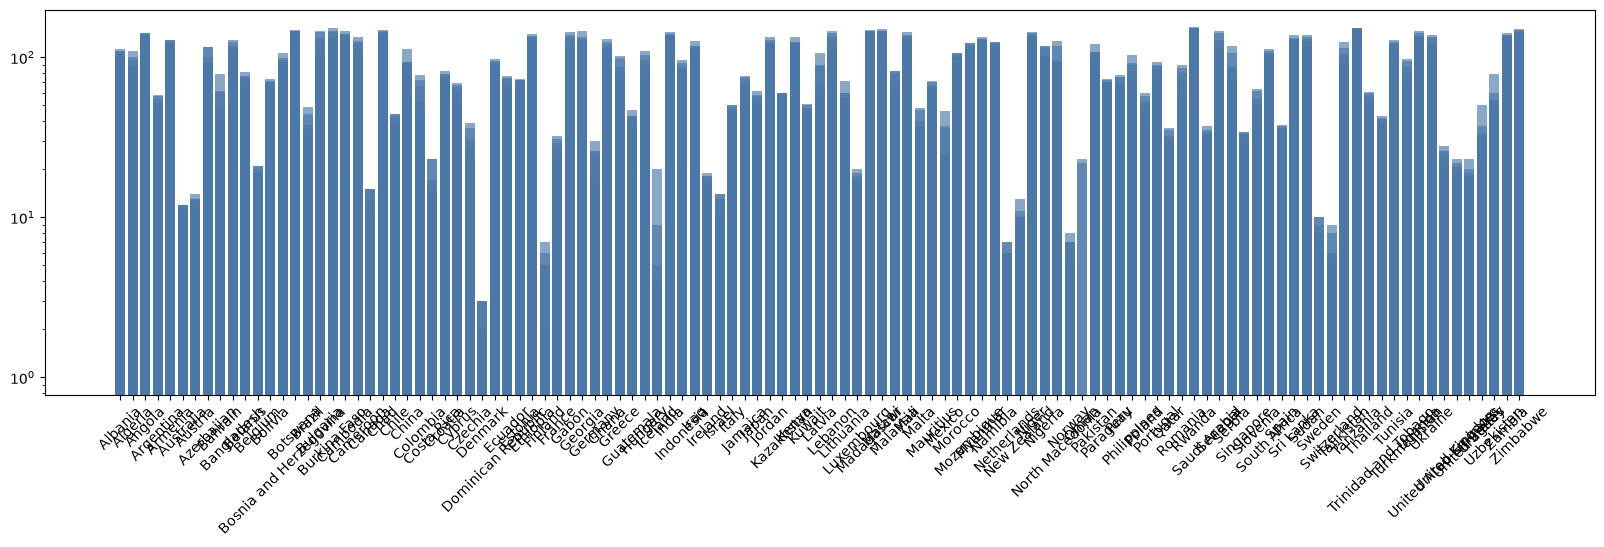

In [148]:
fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(combined_datasets["Country name"], combined_datasets["Rank"], alpha=0.65, color="#4c78a8")
plt.yscale('log')
plt.xticks(rotation=45)
plt.show()

# question 1

     Country name  Ladder score  year
399       Finland         7.741  2023
339       Denmark         7.583  2023
506       Iceland         7.525  2023
1113       Sweden         7.344  2023
566        Israel         7.341  2023
838   Netherlands         7.319  2023
897        Norway         7.302  2023
697    Luxembourg         7.122  2023
1125  Switzerland         7.060  2023
54      Australia         7.057  2023


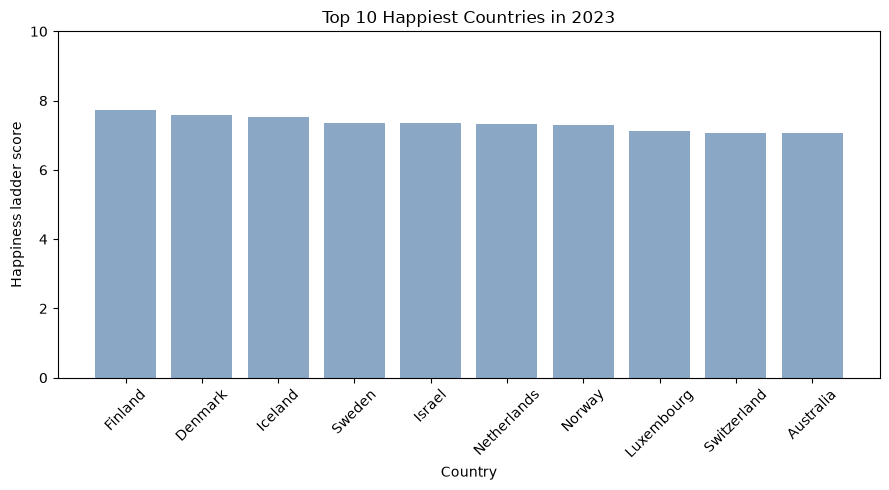

In [149]:
# we use max so that we get the latest year available in the dataset
latest_year = combined_datasets["year"].max()

top10 = (
    combined_datasets[
        combined_datasets["year"] == latest_year
    ]
    .sort_values("Ladder score", ascending=False) # we want a descending order so that we get the highest values first for the top 10
    .head(10)
)

print(top10[["Country name", "Ladder score", "year"]])

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    top10["Country name"],
    top10["Ladder score"],
    color="#4c78a8",
    alpha=0.65
)

ax.set_title(f"Top 10 Happiest Countries in {latest_year}")
ax.set_xlabel("Country")
ax.set_ylabel("Happiness ladder score")
ax.set_ylim(0, 10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

     Country name  Ladder score  year
673       Lebanon         2.707  2023
1299     Zimbabwe         3.341  2023
159      Botswana         3.383  2023
721        Malawi         3.421  2023
1287       Zambia         3.502  2023
1149     Tanzania         3.781  2023
387      Ethiopia         3.861  2023
101    Bangladesh         3.886  2023
1095    Sri Lanka         3.898  2023
518         India         4.054  2023


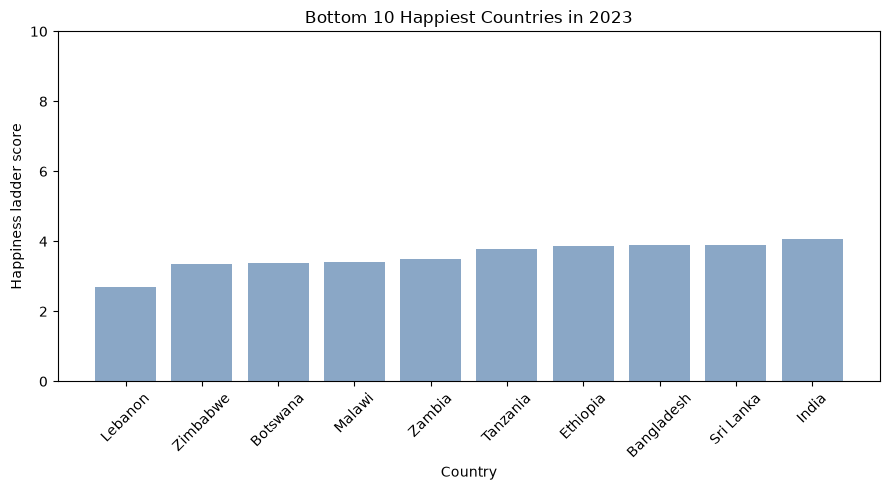

In [150]:
latest_year = combined_datasets["year"].max()

top10 = (
    combined_datasets[
        combined_datasets["year"] == latest_year
    ]
    .sort_values("Ladder score", ascending=True) # and here is the opposite, now we want the lowest values so we need the ascending order
    .head(10)
)

print(top10[["Country name", "Ladder score", "year"]])

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    top10["Country name"],
    top10["Ladder score"],
    color="#4c78a8",
    alpha=0.65
)

ax.set_title(f"Bottom 10 Happiest Countries in {latest_year}")
ax.set_xlabel("Country")
ax.set_ylabel("Happiness ladder score")
ax.set_ylim(0, 10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [151]:
# this function makes a world map with colors based on values
fig = px.choropleth(
    combined_datasets,
    locations="Country name", # this is the variable that contains the geographical locations of each country
    # and this is how we tell the function how to interpret the text in the Country name column 
    locationmode="country names", # (if we were using the codes we should say "ISO-3" here but we're not right now)
    color="Ladder score", # the number variable that indicates how dark the color should be
    animation_frame="year", # this already creates the year slider for us so that we can see the evolution of the values through the years
    color_continuous_scale="Blues", # the HUE
    title="Global Distribution of Happiness by Country"
)

fig.show()

C:\Users\galve\AppData\Local\Temp\ipykernel_16684\39195398.py:2: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


# question 2

In [152]:
latest_year = combined_datasets["year"].max()
dataset_latest_year = combined_datasets[combined_datasets["year"] == latest_year]

figure = px.scatter(
    dataset_latest_year,
    x="gdp_per_capita", # the gdp per capita has bigger values so we placed it in the x axis
    y="Ladder score",
    # after checking each one we think the size is the easiest to the human eye to tell us how different the values are between each other
    # but since we are already using only 2 variables then we dont need more more than 2 channels, so they're both commented
    #size="gdp_per_capita",
    #color="gdp_per_capita",
    hover_name="Country name", # so that we know whhat each bubble represents
    hover_data={
    "gdp_per_capita": ":,.0f", # use a comma for separating the thousands and .0f for now showing decimal values
    "Ladder score": ":.1f" # only one decimal value
    },
    # this needs to be logarithmic scale because the GDP per capita values are numbers that can get very big and they're very disperse
    # if we didn't use this, lower-income countries would be very much on the left side and the relationship with happiness wouldn't be clearly visible
    log_x=True,
    #size_max=50, since we're not changing the size anymore this isn't necessary
    # with this one we can answer our question of knowing where being more rich doesn't change the happiness anymore (doesn't make a difference)
    # it creates a statistical curve tendency and it shows if/where it stops climbing
    trendline="lowess",
    title=f"GDP and Happiness Ladder Score in {latest_year}",
    labels={
        # show the numbers under these labels
        "gdp_per_capita": "GDP per capita (log scale)",
        "Ladder score": "Happiness Ladder Score",
    },
)


figure.update_yaxes(range=[0, 10])
figure.show()

# question 3

In [ ]:
# get a copy of the combined data set and so that we only get what we need to
df_Q3 = combined_datasets[
    [
        "Country name",
        "year",
        "Working hours per worker",
        "Ladder score",
        "gdp_per_capita"
     ]
].copy()

df_Q3 = df_Q3.dropna() # removing any missing values

# removing any invalid values, all values have to be greater than 0
valid_data_Q3 = df_Q3[
    (df_Q3["Working hours per worker"] > 0) &
    (df_Q3["Ladder score"] > 0) &
    (df_Q3["gdp_per_capita"] > 0)
]

# we group every line that belongs to the same country and calculted the median value for the gdp
country_gdp = valid_data_Q3.groupby("Country name")["gdp_per_capita"].median().reset_index() # reset index so the country name is normal column and not an index

# we divide the countries into 3 equal-sized groups based on their median GDP
# and for that we use the function qcut so each income tier has a balanced number of countries
# if we didn't divide them it would be a mess, so we group by GDP that makes more sense
country_gdp["GDP_group"] = pd.qcut(
    country_gdp["gdp_per_capita"],
    q=3,
    labels=["low GDP", "Middle GDP", "High GDP"]
)

# merge the newly created GDP groups back into the main panel dataset using the country name as the matching key
valid_data_Q3 = pd.merge(
    valid_data_Q3,
    country_gdp[["Country name", "GDP_group"]],
    on=["Country name"],
    how="inner"
)

display(valid_data_Q3.head())

,Country name,year,Working hours per worker,Ladder score,gdp_per_capita,GDP_group
0,Albania,2023,2151.97,5.3040,9740.702341,Middle GDP
1,Albania,2022,2160.98,5.2770,7756.961887,Middle GDP
2,Albania,2021,2125.82,5.1990,7242.455131,Middle GDP
3,Albania,2020,2042.15,5.1170,6027.913507,Middle GDP
4,Albania,2019,2142.84,4.8827,6069.439031,Middle GDP


In [ ]:
# Pearson's correlation coefficient is a statistical measure used to evaluate the strength and direction of the linear relationship between two quantitative variables
# in this case, working hours and happiness score
# the coefficient's value always ranges between -1 and 1
# if it's 1, when one variable increases, the other increases in the exact same proportion
# if it's -1, when one variable increases, the other decreases in the exact same proportion
# and if it's 0, it means there is no linear correlation

# here we make the correlations for our global dataset between the working hours and the ladder score of happiness
r_all = valid_data_Q3["Working hours per worker"].corr(valid_data_Q3["Ladder score"])

# and here we make the correlation for each individual GDP group
correlation_of_each_group = valid_data_Q3.groupby("GDP_group",observed=True).apply(
    lambda group: group["Working hours per worker"].corr(group["Ladder score"])
)
print(f"All countries: {r_all:.3f}")
print(correlation_of_each_group)

All countries: -0.406
GDP_group
low GDP       0.212340
Middle GDP   -0.212155
High GDP     -0.381762
dtype: float64


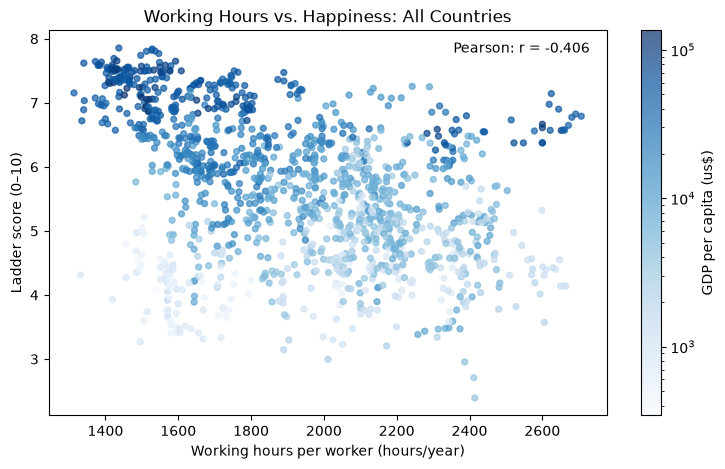

In [ ]:
# map 4 scatterplots , one for all data, three for each group
gdp_min = valid_data_Q3["gdp_per_capita"].min()
gdp_max = valid_data_Q3["gdp_per_capita"].max()


fig, ax = plt.subplots(figsize=(9, 5))
marks = ax.scatter(
    data=valid_data_Q3,
    x="Working hours per worker",
    y="Ladder score",
    c=valid_data_Q3["gdp_per_capita"],
    cmap="Blues",
    # vmin=gdp_min,
    # vmax=gdp_max,
    # once again we use logarithmic scales for the GDP because the values can be very big and are very disperse
    # and the smaller values would be all together and hard do understand
    # by including the minimum and maximum values of the GDP values we can determine the min and max values for the color's luminosity and use it entirely
    norm=LogNorm(
        vmin=valid_data_Q3["gdp_per_capita"].min(),
        vmax=valid_data_Q3["gdp_per_capita"].max()
    ),
    s=18, # points' sizes
    alpha=0.7,
)

fig.colorbar(marks, ax=ax, label="GDP per capita (us$)")

ax.set_title("Working Hours vs. Happiness: All Countries")
ax.set_xlabel("Working hours per worker (hours/year)")
ax.set_ylabel("Ladder score (0–10)")
ax.text(
    0.97,0.97,
    f"Pearson: r = {r_all:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="top"
    )
plt.show()


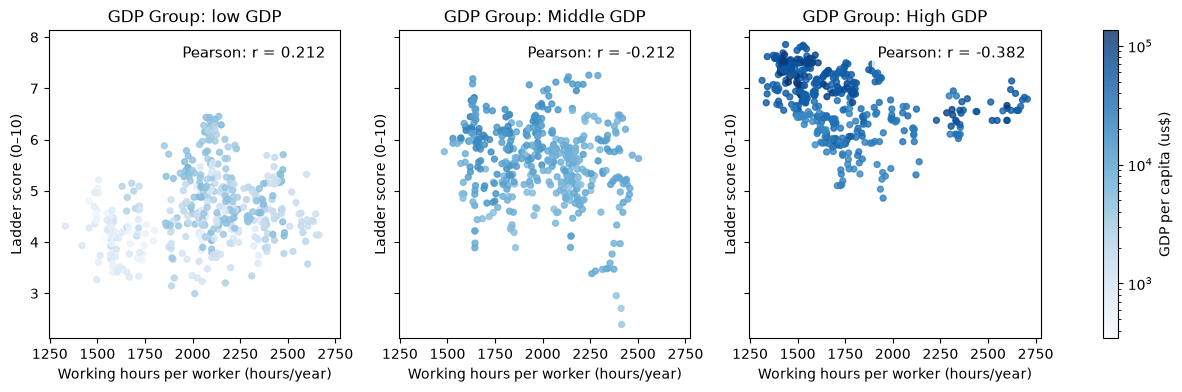

In [170]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)

group_order = ["low GDP","Middle GDP", "High GDP"]
for ax, group_name in zip(axes, group_order):

    group_data = valid_data_Q3[valid_data_Q3["GDP_group"] == group_name]
    marks = ax.scatter(
    data=group_data,
    x="Working hours per worker",
    y="Ladder score",
    c=group_data["gdp_per_capita"],
    cmap="Blues",
    # vmin=gdp_min,
    # vmax=gdp_max,
    norm=LogNorm(
        vmin=valid_data_Q3["gdp_per_capita"].min(),
        vmax=valid_data_Q3["gdp_per_capita"].max()
    ),
    s=18,
    alpha=0.8,
    )
    r = correlation_of_each_group[group_name]
    ax.set_title(f"GDP Group: {group_name}")
    ax.set_xlabel("Working hours per worker (hours/year)")
    ax.set_ylabel("Ladder score (0–10)")

    ax.text(
        0.95, 0.95,
        f"Pearson: r = {r:.3f}",
        transform=ax.transAxes,
        fontsize=11,
        va="top",
        ha="right",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )
fig.colorbar(marks, ax=axes, label="GDP per capita (us$)")


plt.show()